# Full video encoding coverage

The completed cache contains all 7,454 retained videos. This notebook checks recorded source coverage and temporal geometry; it does not load embeddings, train adapters or score test queries. The 2,972 test-query identities were frozen from metadata only. Descriptions and temporal targets remain outside this analysis.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
os.chdir(ROOT)
coverage = json.loads((ROOT / "docs/full-encoding-coverage.json").read_bytes())
assert coverage["videos"] == 7454 and coverage["frame_samples"] == 87356
assert coverage["test_targets_used"] is False
splits = pd.DataFrame(coverage["splits"]).set_index("split")
assert splits.unique_videos.sum() == 7454
assert splits.frame_samples.sum() == 87356
assert splits.loc["test", "queries"] == 2972
assert splits.loc["test", "query_text_encoded"] == False
display(splits)
print(coverage["scope"])

,source_video_ids,unique_videos,frame_samples,candidate_moments,queries,query_text_encoded
split,,,,,,
train,5987,5916,69344,119292,23202,True
val,823,797,9294,15927,3132,True
test,761,741,8718,15039,2972,False


Complete retained noncommercial research availability cohort; not every official video or license category.


## What was encoded

Each retained five-second segment contributes two decoded frames. Contiguous segments form candidate moments, including shorter clips. Training and validation queries are encoded; the test cache contains video features only.

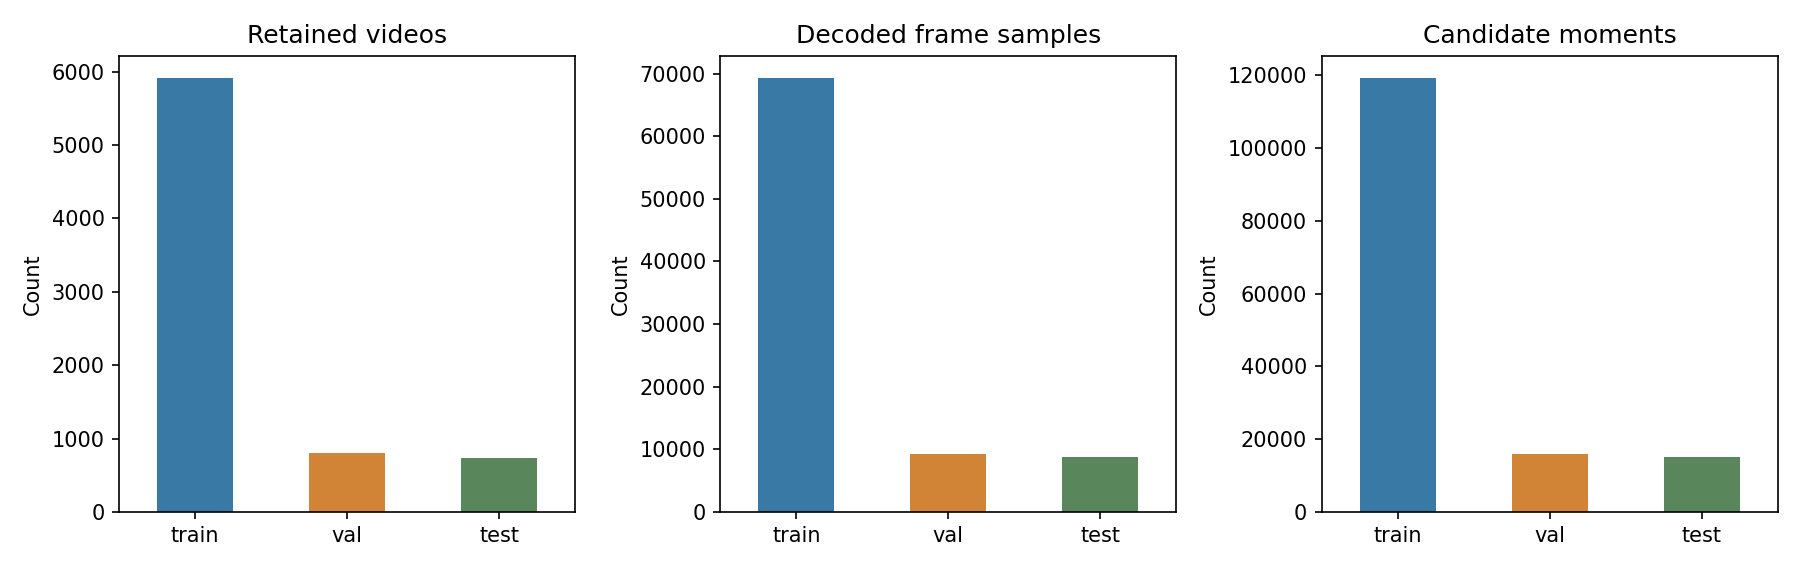

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, column, title in zip(axes, ["unique_videos", "frame_samples", "candidate_moments"], ["Retained videos", "Decoded frame samples", "Candidate moments"]):
    splits[column].plot.bar(ax=ax, rot=0, color=["#3979a5", "#d18435", "#59865b"])
    ax.set(title=title, xlabel="", ylabel="Count")
fig.tight_layout()
figure = ROOT / "docs/figures/full-encoding-coverage.png"
fig.savefig(figure, dpi=150)
plt.close(fig)
display(Image(filename=str(figure)))

## Temporal geometry

A video with n segments has n(n+1)/2 contiguous candidate moments. This counts available candidates, not retrieval success. Static frame pooling does not explicitly model motion order.

In [3]:
segments = pd.DataFrame(coverage["segment_distribution"])
assert segments.videos.sum() == 7454
segments["moments_per_video"] = segments.segments * (segments.segments + 1) // 2
assert int((segments.videos * segments.moments_per_video).sum()) == int(splits.candidate_moments.sum())
display(segments)
print("Encoding wall seconds:", coverage["seconds"])
print("Cache manifest:", coverage["cache_manifest_sha256"])
print("Frozen training protocol:", coverage["protocol_sha256"])
print("Prospective test cohort:", coverage["test_cohort_sha256"])

,segments,videos,moments_per_video
0,5,1046,15
1,6,6408,21


Encoding wall seconds: 23347.183104986
Cache manifest: ea73dced79e83cfc735652d6f8e702011d4e663c3fd9307ef010f66b9120a785
Frozen training protocol: d81c9ef5aa881b04440806702312023135aea8eab9b6a4ba9c10fcab335a39a3
Prospective test cohort: 6e4dcdfe816138cae7803db0977d9b9300a3593cd0d49167b64b2b270d49be38


The metadata audit independently checked every video identity, source hash and frame schedule. Numeric arrays stay in Kaggle; the training runner must verify their file hashes and complete query coverage before fitting. No model-quality conclusion follows from successful encoding.